#### Data Analysis - CNT Filling with phDADQ on Renishaw setup

1. Basic functions

In [ ]:
%matplotlib widget

import os
import re
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from dataclasses import dataclass


# --- 1. DATA STRUCTURE FOR RAMAN MEASUREMENTS ---
@dataclass
class RamanSpectrum:
    filename: str
    folder: str
    df: pd.DataFrame          # Columns: ['RamanShift', 'Intensity']
    label: str = ""
    laser: str = "Unknown"
    grating: str = "Unknown"
    color: str = "#000000"
    linestyle: str = "-"
    scale: float = 1.0        # Manual scaling factor (e.g., for free molecules)
    offset: float = 0.0       # Individual vertical offset

    def __post_init__(self):
        if not self.label:
            self.label = self.filename
        # Auto-extract laser and grating from standard Xplora filename
        laser_match = re.search(r'(532|638|785)\s*nm', self.filename, re.IGNORECASE)
        if laser_match:
            self.laser = f"{laser_match.group(1)} nm"
        grating_match = re.search(r'(\d{3,4})\s*gr', self.filename, re.IGNORECASE)
        if grating_match:
            self.grating = f"{grating_match.group(1)} gr/mm"

    def copy(self):
        return RamanSpectrum(
            filename=self.filename,
            folder=self.folder,
            df=self.df.copy(),
            label=self.label,
            laser=self.laser,
            grating=self.grating,
            color=self.color,
            linestyle=self.linestyle,
            scale=self.scale,
            offset=self.offset
        )

    @property
    def X(self):
        return self.df["RamanShift"].values

    @property
    def Y(self):
        return self.df["Intensity"].values

    @Y.setter
    def Y(self, new_y):
        self.df["Intensity"] = new_y



# --- 3. CORE PROCESSING FUNCTIONS (TRIM, BASELINE, NORMALIZE) ---
def TrimSpectrum(spec_obj, xmin=None, xmax=None):
    """Trims a single RamanSpectrum object to [xmin, xmax]."""
    s = spec_obj.copy()
    mask = np.ones_like(s.X, dtype=bool)
    if xmin is not None:
        mask &= (s.X >= xmin)
    if xmax is not None:
        mask &= (s.X <= xmax)
    s.df = s.df[mask].copy().reset_index(drop=True)
    return s

def SubtractBaseline(spec_obj, poly_order=1, anchor_windows=None):
    """
    Subtracts a baseline from the spectrum.
    - poly_order:0 (minimum value subtraction), 1 (linear), 2+ (polynomial).
    - anchor_windows: list of tuples [(xmin1, xmax1), (xmin2, xmax2)] containing baseline-only regions.
                      If None, uses the first and last 5% of the spectrum.
    """
    s = spec_obj.copy()
    X, Y = s.X, s.Y
    if len(X) == 0:
        return s

    if poly_order == 0:
        s.Y = Y - np.min(Y)
        return s

    if anchor_windows is None:
        n_pts = max(3, int(len(X) * 0.05))
        mask = np.zeros_like(X, dtype=bool)
        mask[:n_pts] = True
        mask[-n_pts:] = True
    else:
        mask = np.zeros_like(X, dtype=bool)
        for wmin, wmax in anchor_windows:
            mask |= ((X >= wmin) & (X <= wmax))

    if np.sum(mask) > poly_order:
        coeffs = np.polyfit(X[mask], Y[mask], poly_order)
        baseline = np.polyval(coeffs, X)
        s.Y = Y - baseline
    return s

def NormalizeSpectrum(spec_obj, xmin=None, xmax=None, mode="M", subtract_min_first=True):
    """
    Normalizes a single RamanSpectrum object within [xmin, xmax].
    - mode: 'M' (Maximum in window, e.g., G-band), 'I' (Integrated area), 'V' (Minimum), 'NONE' (No norm).
    - subtract_min_first: If True, shifts the window minimum to zero before normalizing.
    """
    s = spec_obj.copy()
    if mode is None or mode.upper() == "NONE":
        return s

    X, Y = s.X, s.Y
    mask = np.ones_like(X, dtype=bool)
    if xmin is not None:
        mask &= (X >= xmin)
    if xmax is not None:
        mask &= (X <= xmax)

    X_win, Y_win = X[mask], Y[mask]
    if len(X_win) == 0:
        return s

    if subtract_min_first:
        min_val = np.min(Y_win)
        Y = Y - min_val
        Y_win = Y_win - min_val

    mode = mode.upper()
    if mode == "M":
        factor = np.max(Y_win)
    elif mode == "I":
        factor = np.trapezoid(Y_win, X_win)
    elif mode == "V":
        factor = np.min(Y_win)
    else:
        raise ValueError("Mode must be 'M', 'I', 'V', or 'NONE'")

    if factor != 0:
        s.Y = Y / factor
    return s

2. Loading all data, then I will select the data to compare in excel.

In [19]:
# ==============================================================================
# [ CELL 2 ] : ROBUST DATA LOADER & METADATA MANAGEMENT
# ==============================================================================

# Change this path to the main folder of your setup
BASE_RAMAN_NEW_SETUP = r"H:\FUBerlin\Measurements\Raman Renishaw\CristianB"

def LoadRamanData_NewSetup(base_dir=BASE_RAMAN_NEW_SETUP, sub_folders="ALL"):
    """
    Robust parser for generic 2-column .txt files (ignores headers like '#Wave').
    Returns a dictionary of RamanSpectrum objects keyed by filename.
    """
    spectra_dict = {}

    if not os.path.exists(base_dir):
        print(f"⚠️ Warning: Directory not found -> {base_dir}")
        return spectra_dict

    # Determine folders to scan
    if sub_folders == "ALL":
        target_paths = [base_dir]
    else:
        target_paths = []
        for item in os.listdir(base_dir):
            full_p = os.path.join(base_dir, item)
            if os.path.isdir(full_p) and any(k.lower() in item.lower() for k in sub_folders):
                target_paths.append(full_p)

    # Load and parse data
    for t_path in target_paths:
        for root, dirs, files in os.walk(t_path):
            folder_name = os.path.basename(root)
            for file in sorted(files):
                if not file.lower().endswith(".txt"):
                    continue
                path = os.path.join(root, file)
                
                try:
                    # 1. Read data ignoring multiple spaces/tabs, force numeric
                    df = pd.read_csv(path, sep=r'\s+', header=None, engine='python')
                    df = df.iloc[:, [0, 1]]
                    df.columns = ["RamanShift", "Intensity"]
                    
                    df["RamanShift"] = pd.to_numeric(df["RamanShift"], errors="coerce")
                    df["Intensity"] = pd.to_numeric(df["Intensity"], errors="coerce")
                    
                    # 2. Drop header rows (NaN) and sort
                    df = df.dropna().sort_values("RamanShift").reset_index(drop=True)

                    if len(df) == 0:
                        continue
                    
                    # 3. Create object (laser and grating are auto-assigned in __post_init__ if present in filename)
                    spec_obj = RamanSpectrum(filename=file, folder=folder_name, df=df, label=file)
                    spectra_dict[file] = spec_obj

                except Exception as e:
                    pass
                    
    print(f"✅ Successfully loaded {len(spectra_dict)} Raman spectra.")
    print(f"{(spectra_dict)}")

    return spectra_dict



def assign_metadata(spectra_dict, filename_pattern, laser=None, grating=None, sample_label=None):
    """
    Manually overrides metadata for loaded spectra that match a specific substring in their filename.
    """
    count = 0
    for fname, spec in spectra_dict.items():
        if filename_pattern.lower() in fname.lower():
            if laser: spec.laser = laser
            if grating: spec.grating = grating
            if sample_label: spec.label = sample_label
            count += 1
    print(f"Updated metadata for {count} spectra matching '{filename_pattern}'.")


def FilterSpectra(spectra_dict, laser=None, grating=None, keyword=None):
    """
    Filters the loaded dictionary returning a sub-dictionary of matching RamanSpectrum objects.
    """
    filtered = {}
    for fname, spec in spectra_dict.items():
        match_laser = (laser is None) or (spec.laser == laser)
        match_grating = (grating is None) or (spec.grating == grating)
        match_keyword = (keyword is None) or (keyword.lower() in fname.lower())
        
        if match_laser and match_grating and match_keyword:
            filtered[fname] = spec
            
    print(f"🔍 Found {len(filtered)} spectra matching criteria.")
    return filtered


# --- EXECUTION ---
# 1. Load the data
raman_spectra = LoadRamanData_NewSetup(BASE_RAMAN_NEW_SETUP, sub_folders="ALL")

# 2. (Optional) Fix metadata manually if the filename convention was broken
# assign_metadata(raman_spectra, "F005LP", laser="532 nm", sample_label="F005LP 6FBz@P2")

# 3. Filter specific datasets to analyze later
# spectra_532nm = FilterSpectra(raman_spectra, laser="532 nm")
# spectra_phDADQ = FilterSpectra(raman_spectra, keyword="phDADQ")

✅ Successfully loaded 9 Raman spectra.
{'BluephDADQ.txt': RamanSpectrum(filename='BluephDADQ.txt', folder='20261116_Raman_P2_F006WA_phDADQ', df=       RamanShift  Intensity
0        2.519531        0.0
1        4.322266        0.0
2        6.125000        0.0
3        7.927734        0.0
4        9.730469        0.0
...           ...        ...
2401  3498.759766        0.0
2402  3499.927734        0.0
2403  3501.095703        0.0
2404  3502.263672        0.0
2405  3503.431641        0.0

[2406 rows x 2 columns], label='BluephDADQ.txt', laser='Unknown', grating='Unknown', color='#000000', linestyle='-', scale=1.0, offset=0.0), 'BluephDADQ1.txt': RamanSpectrum(filename='BluephDADQ1.txt', folder='20261116_Raman_P2_F006WA_phDADQ', df=       RamanShift   Intensity
0        2.519531  249.503723
1        4.322266  155.276932
2        6.125000   81.813568
3        7.927734   33.286564
4        9.730469   36.067451
...           ...         ...
2401  3498.759766  282.399841
2402  3499.927734  2

3. Plotting Function

In [17]:
# ==============================================================================
# [ CELL 3 ] : FLEXIBLE PLOTTING ENGINE (SUPPORTS FREE MOLECULE RESCALING)
# ==============================================================================
# --- 2. PUBLICATION / POSTER STYLE CONFIGURATION ---
poster_style = {
    "figsize": (4, 3),
    "dpi": 300,
    "font_size": 10,
    "title_size": 11,
    "label_size": 11,
    "legend_size": 8,
    "line_width": 1.0,
    "font_family": "Calibri",
    "grid": False,
    "colors": ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"],
    "linestyles": ["-", "--", "-.", ":"]
}

def PlotRamanConfig(
    config, spectra_dict=None, style=poster_style, offset_step=0.0,
    xmin=None, xmax=None, ymin=None, ymax=None,
    norm_xmin=None, norm_xmax=None, norm_mode="M", subtract_min_first=True,
    vlines=None, rbm_laser_nm=None, hide_yticks=True, legend_ncol=1,
    title=None, save_path=None
):
    """
    Plots a list of spectra with full control over individual scaling and trimming.
    
    Each tuple in `config` can have 4, 5, or 6 elements:
      1. (file_or_obj, label, color, linestyle)
      2. (file_or_obj, label, color, linestyle, manual_scale)
      3. (file_or_obj, label, color, linestyle, manual_scale, (ind_xmin, ind_xmax))
         -> Note: If manual_scale != 1.0, you can also pass 'RAW' or a tuple to skip global normalization
            or scale it relative to the normalized peak!
    """
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    plt.rcParams.update({"font.size": style["font_size"], "font.family": style["font_family"]})

    processed_list = []

    for i, item in enumerate(config):
        # Unpack tuple flexibly (supports 4, 5, or 6 items)
        source, label, color, ls = item[0], item[1], item[2], item[3]
        manual_scale = item[4] if len(item) > 4 else 1.0
        ind_trim = item[5] if len(item) > 5 else None

        # Retrieve RamanSpectrum object
        if isinstance(source, RamanSpectrum):
            s = source.copy()
        elif isinstance(source, str) and spectra_dict and source in spectra_dict:
            s = spectra_dict[source].copy()
        else:
            print(f"⚠️ Spectrum not found: {source}")
            continue

        # 1. Global Normalization (e.g., G-band between 1500 and 1650 cm-1)
        if norm_mode and norm_mode.upper() != "NONE":
            s = NormalizeSpectrum(s, xmin=norm_xmin, xmax=norm_xmax, mode=norm_mode, subtract_min_first=subtract_min_first)

        # 2. Global Trim
        if xmin is not None or xmax is not None:
            s = TrimSpectrum(s, xmin=xmin, xmax=xmax)

        # 3. Individual Trim (e.g., cut noisy region of free molecule spectrum)
        if ind_trim is not None:
            s = TrimSpectrum(s, xmin=ind_trim[0], xmax=ind_trim[1])

        # 4. Apply Manual Scale Factor & Offset
        s.Y = (s.Y * manual_scale) + (i * offset_step)
        s.label = label
        s.color = color
        s.linestyle = ls
        processed_list.append(s)

        # Plot curve
        ax.plot(s.X, s.Y, label=s.label, color=s.color, linestyle=s.linestyle, linewidth=style["line_width"])

    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=style["label_size"])
    ax.set_ylabel("Intensity (a.u.)", fontsize=style["label_size"])

    if xmin is not None or xmax is not None:
        ax.set_xlim(xmin, xmax)
    if ymin is not None or ymax is not None:
        ax.set_ylim(ymin, ymax)
    if style.get("grid", False):
        ax.grid(True, alpha=0.3)
    if hide_yticks:
        ax.set_yticklabels([])
        ax.set_yticks([])

    # Optional vertical reference lines (e.g., pristine G+ or molecule peaks)
    if vlines is not None:
        for x_val in vlines:
            ax.axvline(x=x_val, linewidth=0.7, linestyle='--', color='#555555', alpha=0.8, zorder=0)

    # Optional top axis showing SWCNT Diameter (nm) if plotting the RBM region (100 - 400 cm-1)
    if rbm_laser_nm is not None or (xmin is not None and xmax is not None and xmax <= 450):
        ax_top = ax.twiny()
        ax_top.set_xlim(ax.get_xlim())
        rbm_ticks = np.array([150, 200, 250, 300, 350])
        rbm_ticks = rbm_ticks[(rbm_ticks >= ax.get_xlim()[0]) & (rbm_ticks <= ax.get_xlim()[1])]
        # Standard relation: omega_RBM = 228 / d_t + 16
        diam_labels = [f"{228.0 / (w - 16.0):.2f}" for w in rbm_ticks]
        ax_top.set_xticks(rbm_ticks)
        ax_top.set_xticklabels(diam_labels, fontsize=style["font_size"] - 1)
        ax_top.set_xlabel("SWCNT Diameter $d_t$ (nm)", fontsize=style["label_size"] - 1)

    if title:
        ax.set_title(title, fontsize=style["title_size"])

    ax.legend(fontsize=style["legend_size"], ncol=legend_ncol, frameon=False)
    plt.tight_layout()

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=style["dpi"], bbox_index="tight")
        print(f"💾 Saved figure to: {save_path}")

    plt.show()
    return processed_list

## 532nm Data - FluorinatedMol@CNTs vs References (Water-filled, Empty, Alkanes, etc...)

In [18]:
# --- 2. PUBLICATION / POSTER STYLE CONFIGURATION ---
poster_style = {
    "figsize": (4, 3),
    "dpi": 300,
    "font_size": 10,
    "title_size": 11,
    "label_size": 11,
    "legend_size": 8,
    "line_width": 1.0,
    "font_family": "Calibri",
    "grid": False,
    "colors": ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"],
    "linestyles": ["-", "--", "-.", ":"]
}




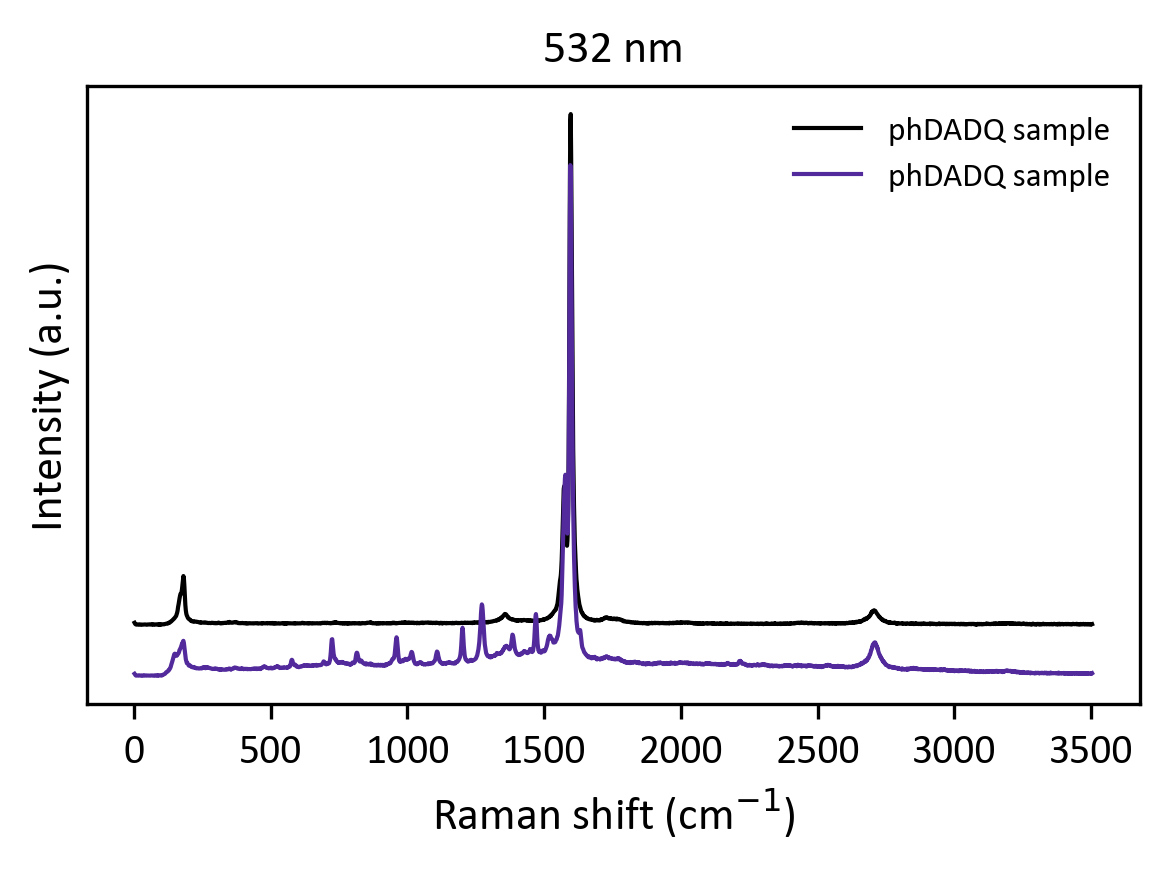

[RamanSpectrum(filename='P2Ref_473nm.txt', folder='20261116_Raman_P2_F006WA_phDADQ', df=       RamanShift  Intensity
 0        2.519531   0.003836
 1        4.322266   0.002008
 2        6.125000   0.000925
 3        7.927734   0.000383
 4        9.730469   0.000700
 ...           ...        ...
 2401  3498.759766   0.001497
 2402  3499.927734   0.000661
 2403  3501.095703   0.001218
 2404  3502.263672   0.000870
 2405  3503.431641   0.001114
 
 [2406 rows x 2 columns], label='phDADQ sample', laser='Unknown', grating='Unknown', color='#000000', linestyle='-', scale=1.0, offset=0.0),
 RamanSpectrum(filename='F006WA_phDADQ_473nm.txt', folder='20261116_Raman_P2_F006WA_phDADQ', df=       RamanShift  Intensity
 0        2.519531  -0.096048
 1        4.322266  -0.097610
 2        6.125000  -0.098829
 3        7.927734  -0.099633
 4        9.730469  -0.099587
 ...           ...        ...
 2401  3498.759766  -0.095502
 2402  3499.927734  -0.095714
 2403  3501.095703  -0.096352
 2404  3502.263

In [22]:
config_532_comparison = [
('P2Ref_473nm.txt', 'phDADQ sample', "#000000", '-'),
('F006WA_phDADQ_473nm.txt', 'phDADQ sample', "#522A9B", '-'),
]


PlotRamanConfig(
    style=poster_style,
    config=config_532_comparison,
    spectra_dict=raman_spectra,
    offset_step=-0.1,
    #xmin=100, xmax=2800,
    #norm_xmin=1550, norm_xmax=1620, norm_mode="M",  # Normalize all to G-band maximum
    #vlines=[1592],                                  # Vertical guide on pristine G+ peak
    hide_yticks=True,
    title="532 nm"
)
